# BIOT 6900 · Module 6, Part 3 — Graded Assignment: PRS Portability on Real Data

**Disease: colorectal cancer** (carried forward from my Module 2–4 colon adenocarcinoma work, in place of Alzheimer's, as approved).

You now run the full workflow yourself, on **real 1000 Genomes genotypes** with a **published colorectal cancer score from the PGS Catalog** (**PGS000148**, CRC63, Jeon et al. *Gastroenterology* 2018: 63 SNPs, weights estimated in European-ancestry samples only): harmonize the alleles, compute the PRS, and evaluate discrimination, calibration, and the portability problem across ancestry groups. Then you write it up.

All **# TODO** cells are completed; the notebook was run with **Kernel → Restart & Run All**.


### Data (built by `prepare_crc_data.py`, not the Canvas zip)

The Canvas `data.zip` holds only the 22 Alzheimer's SNPs, so a colorectal score has nothing to match. I rebuilt the same four files from the same sources the professor used (PGS Catalog + 1000 Genomes phase 3, GRCh37), for the **same 2,336 people, ancestry labels and ages** as the Canvas cohort. The phenotype is simulated with the professor's recipe from the Canvas README, unchanged except for the score. Read `data/README.md` for sources, the simulation and the checksums.

| File | Columns | Notes |
|---|---|---|
| `genotypes.csv` | one column per variant, rows = people | dosages 0/1/2, **counting the ALT allele** |
| `variants.csv` | `variant`, `ref`, `alt` | the REF/ALT nucleotides, same build as the genotypes |
| `score.csv` | `variant`, `effect_allele`, `other_allele`, `weight` | PGS000148 (CRC63); alleles as published |
| `meta.csv` | `ancestry`, `age`, `phenotype` | ancestry = EUR/AFR/EAS/SAS/AMR; phenotype is 1 = case |

> **This is a graded run, so it must use real data.** The loader **stops with an error** unless all four files are present. `USE_DEMO` is `False`.

> ⚠️ **The phenotype is simulated, and so is age.** 1000 Genomes has no disease labels and no ages. The PRS and its distribution across ancestries are computed on real inputs; AUC and calibration use the simulated label and are illustrative.

> **Proof of real data.** Section 2 prints a fingerprint (file checksums, counts). It is pasted into the report.


## 0. Setup

In [1]:
import os, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

NU_RED, NU_COOL, NU_GREY = "#C8102E", "#1E2028", "#6E7178"
POP_COLORS = {"EUR":"#1E2028","AFR":"#C8102E","EAS":"#6E7178","SAS":"#A4804A","AMR":"#9AA0A6"}
rng = np.random.default_rng(6900)

USE_DEMO = False     # graded run on real data

## 1. Load the data  *(provided, do not edit)*

Strict loader: with `USE_DEMO = False` it requires all four real files and refuses to run otherwise. The demo path is clearly labelled and is never acceptable for grading.

In [2]:
BASES = np.array(list("ACGT"))
def _make_demo_cohort(seed=6900):
    r = np.random.default_rng(seed)
    pops = {"EUR":(600,0.92,0.05,0.14),"AFR":(600,0.40,0.15,0.22),"EAS":(500,0.58,0.12,0.09),
            "SAS":(500,0.66,0.09,0.09),"AMR":(500,0.55,0.07,0.11)}   # n, tag-rho, drift, APOE freq
    M = 80
    b = r.normal(0, 0.15, M); b[0] = 1.3
    w_true = b * 0.92
    base = r.uniform(0.15, 0.5, M)
    Gt, Gc, anc, ages = [], [], [], []
    for pop,(n,rho,drift,apoe) in pops.items():
        f = np.clip(base + r.normal(0,drift,M), 0.03, 0.97); f[0] = apoe; thr = norm.ppf(f)
        gc = np.zeros((n,M)); gt = np.zeros((n,M))
        for _ in range(2):
            L = r.normal(size=(n,M)); Z = r.normal(size=(n,M))
            gc += (L<thr); gt += ((rho*L + np.sqrt(1-rho**2)*Z) < thr)
        Gt.append(gt); Gc.append(gc); anc += [pop]*n; ages.append(r.normal(60,8,n))
    Gt = np.vstack(Gt); Gc = np.vstack(Gc); anc = np.array(anc); age = np.concatenate(ages)
    lin = Gc @ b + 0.03*(age-60); b0 = np.log(0.30/0.70) - lin.mean()
    y = (r.uniform(size=len(lin)) < 1/(1+np.exp(-(b0+lin)))).astype(int)
    variants = [f"rs_tag_{i:03d}" for i in range(M)]
    # real nucleotides: pick ref != alt; dosages count ALT
    ref = r.choice(BASES, M); alt = np.array([r.choice(BASES[BASES!=ref[i]]) for i in range(M)])
    geno = pd.DataFrame(Gt, columns=variants)
    vtab = pd.DataFrame({"variant":variants, "ref":ref, "alt":alt})
    # 25% of rows report the REF allele as effect allele, with the weight's sign reversed
    report_ref = r.random(M) < 0.25
    eff = np.where(report_ref, ref, alt); oth = np.where(report_ref, alt, ref)
    wrep = np.where(report_ref, -w_true, w_true)
    score = pd.DataFrame({"variant":variants, "effect_allele":eff, "other_allele":oth, "weight":wrep})
    meta  = pd.DataFrame({"ancestry":anc, "age":age, "phenotype":y})
    return geno, vtab, score, meta

REAL_FILES = ["genotypes.csv","variants.csv","score.csv","meta.csv"]
def _sha8(path):
    h = hashlib.sha256(open(path,"rb").read()).hexdigest()[:8]
    return h

def load_data(path="data"):
    present = [f for f in REAL_FILES if os.path.exists(os.path.join(path,f))]
    if not USE_DEMO:
        missing = [f for f in REAL_FILES if f not in present]
        if missing:
            raise FileNotFoundError(
                "GRADED RUN requires all four files in ./%s/ . Missing: %s .  "
                "Set USE_DEMO=True ONLY to prototype on synthetic data; it must be False for submission."
                % (path, ", ".join(missing)))
        geno=pd.read_csv(os.path.join(path,"genotypes.csv"))
        vtab=pd.read_csv(os.path.join(path,"variants.csv"))
        score=pd.read_csv(os.path.join(path,"score.csv"))
        meta=pd.read_csv(os.path.join(path,"meta.csv"))
        info={"source":"REAL","hashes":{f:_sha8(os.path.join(path,f)) for f in REAL_FILES}}
        print("="*64); print("  RUNNING ON REAL DATA"); print("="*64)
    else:
        print("="*64); print("  USE_DEMO=True  ->  SYNTHETIC demo cohort  (NOT FOR GRADING)"); print("="*64)
        geno,vtab,score,meta=_make_demo_cohort(); info={"source":"DEMO","hashes":None}
    return geno, vtab, score, meta, info

geno, variants, score, meta, info = load_data()

  RUNNING ON REAL DATA


## 2. Proof of real data  *(paste this block into your report)*

In [3]:
print("source      :", info["source"])
print("people      :", len(meta))
print("score size  :", len(score), "variants")
print("by ancestry :", dict(meta["ancestry"].value_counts()))
if info["source"] == "REAL":
    for f,h in info["hashes"].items():
        print(f"  {f}: sha256 {h}")
else:
    print("  DEMO cohort - not acceptable for your graded submission")

source      : REAL
people      : 2336
score size  : 62 variants
by ancestry : {'AFR': np.int64(500), 'EAS': np.int64(500), 'EUR': np.int64(500), 'SAS': np.int64(489), 'AMR': np.int64(347)}
  genotypes.csv: sha256 5617fc3c
  variants.csv: sha256 0b8c8747
  score.csv: sha256 309987fb
  meta.csv: sha256 8dbbb462


## 3.1 Harmonize alleles: keep / flip / drop

For each variant, compare the score's `effect_allele` with that variant's REF and ALT:
- equals **ALT** -> keep the dosage and weight as is,
- equals **REF** -> flip the dosage (`2 - dosage`),
- equals **neither** -> drop the variant.

Report how many you used, flipped, and dropped.

In [4]:
shared = [v for v in score["variant"] if v in geno.columns]
G = geno[shared].to_numpy(dtype=float).copy()
s = score.set_index("variant").loc[shared]
v = variants.set_index("variant").loc[shared]
eff = s["effect_allele"].to_numpy()
ref = v["ref"].to_numpy(); alt = v["alt"].to_numpy()
w = s["weight"].to_numpy()

# build three boolean masks over the variants
keep = (eff == alt)             # effect allele is the counted (ALT) allele
flip = (eff == ref)             # effect allele is REF -> count it with 2 - dosage
drop = ~(keep | flip)           # matches neither (strand / build mismatch)

G[:, flip] = 2 - G[:, flip]
dropped = [v for v, d in zip(shared, drop) if d]
G, w = G[:, ~drop], w[~drop]
print("flipped:", [v for v, f in zip(shared, flip) if f])
print("dropped:", dropped)

print(f"used {int((keep|flip).sum())}  flipped {int(flip.sum())}  dropped {int(drop.sum())}")

flipped: ['rs10911251', 'rs72647484', 'rs10936599', 'rs2450115', 'rs10505477', 'rs6983267', 'rs7014346', 'rs719725', 'rs10904849', 'rs10795668', 'rs4919687', 'rs1535', 'rs174537', 'rs174550', 'rs4246215', 'rs3802842', 'rs10774214', 'rs11064437', 'rs11169552', 'rs7136702', 'rs1957636', 'rs4779584', 'rs79900961', 'rs9929218', 'rs4939827', 'rs10411210', 'rs6066825', 'rs6061231']
dropped: ['rs7229639']
used 61  flipped 28  dropped 1


## 3.2 Compute the PRS

In [5]:
# PRS = dosages times weights, summed per person (hint: G @ w)
prs = G @ w
prs_z = (prs - prs.mean()) / prs.std()
meta["prs"] = prs_z
print("PRS computed for", len(prs_z), "people")

PRS computed for 2336 people


## 3.3 Distribution shift and a single cutoff

Plot the PRS distribution per ancestry, then show what one fixed cutoff does: take the whole-cohort top-10% PRS value and report the fraction of each ancestry group above it.

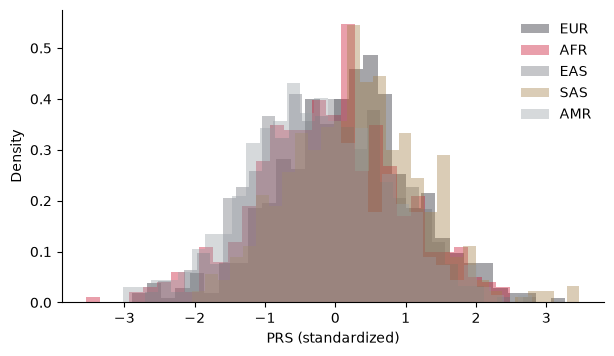

pooled top-10% cutoff: PRS > 1.282


            n  mean PRS  SD PRS  % above cutoff  % cases
ancestry                                                
EUR       500      0.16    0.98            12.2     30.0
AFR       500     -0.09    1.00             8.4     26.6
EAS       500     -0.17    0.96             7.2     28.2
SAS       489      0.30    0.93            14.9     38.0
AMR       347     -0.28    1.02             6.3     26.2


In [6]:
fig, ax = plt.subplots(figsize=(7,3.8))
for pop, c in POP_COLORS.items():
    sub = meta.loc[meta.ancestry==pop, "prs"]
    ax.hist(sub, bins=30, density=True, alpha=0.4, color=c, label=pop)
ax.set_xlabel("PRS (standardized)"); ax.set_ylabel("Density"); ax.legend(frameon=False)
for sp in ("top","right"): ax.spines[sp].set_visible(False)
os.makedirs("figures", exist_ok=True); fig.savefig("figures/prs_by_ancestry.png", dpi=200, bbox_inches="tight")
plt.show()

cutoff = np.quantile(meta["prs"], 0.90)
print(f"pooled top-10% cutoff: PRS > {cutoff:.3f}")
summary = pd.DataFrame({
    "n": meta.groupby("ancestry").size(),
    "mean PRS": meta.groupby("ancestry")["prs"].mean().round(2),
    "SD PRS": meta.groupby("ancestry")["prs"].std().round(2),
    "% above cutoff": (100*(meta["prs"] > cutoff).groupby(meta["ancestry"]).mean()).round(1),
    "% cases": (100*meta.groupby("ancestry")["phenotype"].mean()).round(1),
})
print(summary.loc[list(POP_COLORS)])

## 3.4 Discrimination by ancestry

In [7]:
y = meta["phenotype"].to_numpy()
prs_z = meta["prs"].to_numpy()
print(f"Overall AUC: {roc_auc_score(y, prs_z):.3f}")
for pop in POP_COLORS:
    m = (meta.ancestry==pop).to_numpy()
    print(f"  {pop}: AUC = {roc_auc_score(y[m], prs_z[m]):.3f}   (n={m.sum()}, cases={y[m].sum()})")

Overall AUC: 0.647
  EUR: AUC = 0.685   (n=500, cases=150)
  AFR: AUC = 0.567   (n=500, cases=133)
  EAS: AUC = 0.689   (n=500, cases=141)
  SAS: AUC = 0.606   (n=489, cases=186)
  AMR: AUC = 0.670   (n=347, cases=91)


## 3.5 Calibration by ancestry

Fit the risk model **in EUR only**, apply it to everyone, and draw one calibration curve per ancestry. A model honest in EUR is often not honest elsewhere. The helper is provided.

In [8]:
def calibration_points(y, p, bins=5):
    edges = np.quantile(p, np.linspace(0,1,bins+1)); edges[-1]+=1e-9
    idx = np.clip(np.digitize(p, edges)-1, 0, bins-1)
    xs, ys = [], []
    for b in range(bins):
        m = idx==b
        if m.sum() > 5: xs.append(p[m].mean()); ys.append(y[m].mean())
    return np.array(xs), np.array(ys)

EUR-fitted model: intercept -1.054, slope per SD 0.720


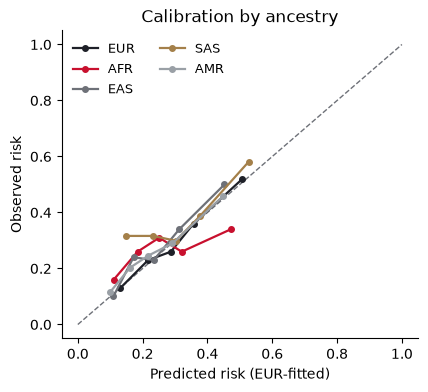

mean predicted vs observed risk (EUR-fitted model):
  EUR: predicted 0.300   observed 0.300   ratio O/E 1.00   pred range 0.04-0.79
        quintile pred: [0.13 0.22 0.29 0.36 0.51]  obs: [0.13 0.23 0.26 0.36 0.52]
  AFR: predicted 0.268   observed 0.266   ratio O/E 0.99   pred range 0.03-0.68
        quintile pred: [0.11 0.18 0.25 0.32 0.47]  obs: [0.16 0.26 0.31 0.26 0.34]
  EAS: predicted 0.256   observed 0.282   ratio O/E 1.10   pred range 0.05-0.73
        quintile pred: [0.11 0.17 0.23 0.31 0.45]  obs: [0.1  0.24 0.23 0.34 0.5 ]
  SAS: predicted 0.318   observed 0.380   ratio O/E 1.20   pred range 0.07-0.81
        quintile pred: [0.15 0.23 0.3  0.38 0.53]  obs: [0.32 0.32 0.3  0.39 0.58]
  AMR: predicted 0.244   observed 0.262   ratio O/E 1.08   pred range 0.04-0.72
        quintile pred: [0.1  0.16 0.22 0.29 0.45]  obs: [0.11 0.2  0.25 0.29 0.46]


In [9]:
prs_z = meta["prs"].to_numpy(); y = meta["phenotype"].to_numpy()
eur = (meta.ancestry=="EUR").to_numpy()

# fit LogisticRegression on EUR only (prs_z[eur] -> y[eur]), then predict_proba for everyone
model = LogisticRegression().fit(prs_z[eur].reshape(-1,1), y[eur])
p_hat = model.predict_proba(prs_z.reshape(-1,1))[:,1]
print(f"EUR-fitted model: intercept {model.intercept_[0]:.3f}, slope per SD {model.coef_[0,0]:.3f}")

fig, ax = plt.subplots(figsize=(4.6,4.0))
ax.plot([0,1],[0,1], ls="--", color=NU_GREY, lw=1)
for pop, c in POP_COLORS.items():
    m = (meta.ancestry==pop).to_numpy()
    xs, ys = calibration_points(y[m], p_hat[m])
    ax.plot(xs, ys, marker="o", ms=4, color=c, lw=1.6, label=pop)
ax.set_xlabel("Predicted risk (EUR-fitted)"); ax.set_ylabel("Observed risk")
ax.set_title("Calibration by ancestry"); ax.legend(frameon=False, ncol=2, fontsize=9)
for sp in ("top","right"): ax.spines[sp].set_visible(False)
fig.savefig("figures/calibration_by_ancestry.png", dpi=200, bbox_inches="tight")
plt.show()

print("mean predicted vs observed risk (EUR-fitted model):")
for pop in POP_COLORS:
    m = (meta.ancestry==pop).to_numpy()
    xs, ys = calibration_points(y[m], p_hat[m])
    print(f"  {pop}: predicted {p_hat[m].mean():.3f}   observed {y[m].mean():.3f}   "
          f"ratio O/E {y[m].mean()/p_hat[m].mean():.2f}   pred range {p_hat[m].min():.2f}-{p_hat[m].max():.2f}")
    print("        quintile pred:", np.round(xs,2), " obs:", np.round(ys,2))

## 3.6 Does the PRS add to age alone?

In [10]:
age_z = ((meta["age"]-meta["age"].mean())/meta["age"].std()).to_numpy()
y = meta["phenotype"].to_numpy()
# 5-fold cross-validated AUC for age only, and for age + PRS
prs_z = meta["prs"].to_numpy()
auc_age     = cross_val_score(LogisticRegression(), age_z.reshape(-1,1), y, cv=5, scoring="roc_auc").mean()
auc_age_prs = cross_val_score(LogisticRegression(), np.column_stack([age_z, prs_z]), y, cv=5, scoring="roc_auc").mean()
print(f"AUC age only:  {auc_age:.3f}")
print(f"AUC age + PRS: {auc_age_prs:.3f}")

AUC age only:  0.579
AUC age + PRS: 0.666


## 3.8 Supporting analyses  *(added by me, used in the report)*

1. **Why the distributions shift:** effect-allele frequency per ancestry for each SNP, and how much each SNP moves each group's mean PRS relative to EUR (in PRS SD units).
2. **Why discrimination drops:** the simulation log records each tag's r² with its causal SNP in every ancestry.
3. **What the single cutoff does:** case rate if flagged vs not flagged, share of each group's cases caught, and each group's own top-10% value.
4. **Incremental value within each ancestry:** cross-validated AUC for age only vs age + PRS, per group.
5. **Noise check:** bootstrap 95% confidence intervals for each group's AUC.


In [11]:
# 1. allele-frequency differences behind the shift (G is already harmonized to count the effect allele)
anc = meta["ancestry"].to_numpy()
used = [v for v, d in zip(shared, drop) if not d]
eaf = pd.DataFrame({p: G[anc == p].mean(axis=0) / 2 for p in POP_COLORS}, index=used)
eaf["weight"] = w
sd_raw = prs.std()
for p in ["AFR", "EAS", "SAS", "AMR"]:
    eaf[f"shift_{p}"] = 2 * (eaf[p] - eaf["EUR"]) * eaf["weight"] / sd_raw
print("mean-PRS shift vs EUR, summed over SNPs:",
      {p: round(eaf[f"shift_{p}"].sum(), 2) for p in ["AFR", "EAS", "SAS", "AMR"]})
for p in ["AFR", "EAS"]:
    print(f"\nlargest contributors to the {p} shift:")
    print(eaf.reindex(eaf[f"shift_{p}"].abs().sort_values(ascending=False).index)
             [["EUR", p, "weight", f"shift_{p}"]].head(6).round(3).to_string())


mean-PRS shift vs EUR, summed over SNPs: {'AFR': np.float64(-0.25), 'EAS': np.float64(-0.33), 'SAS': np.float64(0.14), 'AMR': np.float64(-0.44)}

largest contributors to the AFR shift:
              EUR    AFR  weight  shift_AFR
rs11064437  0.992  0.683   0.218     -0.412
rs4246215   0.631  0.979  -0.165     -0.351
rs1535      0.651  0.894   0.184      0.274
rs174550    0.654  0.979   0.134      0.266
rs4779584   0.206  0.613   0.105      0.261
rs3184504   0.536  0.981   0.089      0.242

largest contributors to the EAS shift:
              EUR    EAS  weight  shift_EAS
rs4779584   0.206  0.811   0.105      0.389
rs11064437  0.992  0.722   0.218     -0.360
rs3184504   0.536  0.997   0.089      0.251
rs1535      0.651  0.436   0.184     -0.242
rs1800469   0.686  0.452   0.151     -0.216
rs11196172  0.120  0.648   0.062      0.200


In [12]:
# 2. tag-causal LD per ancestry, from the simulation log
sim = pd.read_csv("data/simulation_log.csv")
r2cols = [f"r2_{p}" for p in POP_COLORS]
print("mean tag-causal r2:", sim[r2cols].mean().round(2).to_dict())
print("tags with r2 < 0.2:", {p: int((sim[f"r2_{p}"] < 0.2).sum()) for p in POP_COLORS})
sim["abs_w"] = sim["weight"].abs()
wr2 = {p: round(float((sim["abs_w"] * sim[f"r2_{p}"]).sum() / sim["abs_w"].sum()), 2) for p in POP_COLORS}
print("weight-averaged r2:", wr2)
print("\nlargest-weight tags and their r2:")
print(sim.sort_values("abs_w", ascending=False)[["tag", "weight", "causal"] + r2cols].head(8).to_string(index=False))


mean tag-causal r2: {'r2_EUR': 0.83, 'r2_AFR': 0.45, 'r2_EAS': 0.76, 'r2_SAS': 0.77, 'r2_AMR': 0.74}
tags with r2 < 0.2: {'EUR': 0, 'AFR': 25, 'EAS': 7, 'SAS': 2, 'AMR': 2}
weight-averaged r2: {'EUR': 0.83, 'AFR': 0.46, 'EAS': 0.73, 'SAS': 0.75, 'AMR': 0.75}

largest-weight tags and their r2:
       tag  weight       causal  r2_EUR  r2_AFR  r2_EAS  r2_SAS  r2_AMR
rs11064437   0.218   12:6982162   1.000   1.000   1.000   1.000   1.000
rs16892766   0.200  8:117642990   0.689   0.058   0.014   0.446   0.612
rs73208120   0.188 12:117654010   0.637   0.164     NaN   0.168   0.287
    rs1535   0.184  11:61570783   0.971   0.120   0.993   0.942   0.948
 rs4246215  -0.165  11:61585144   0.903   0.950   0.993   0.975   0.979
 rs1800469   0.151  19:41864509   0.996   0.753   0.956   0.991   0.983
 rs3217810   0.143   12:4388271   1.000   1.000   1.000   1.000   1.000
  rs174550   0.134  11:61573684   1.000   1.000   0.997   1.000   1.000


In [13]:
# 3. what the pooled top-10% cutoff means in each group
prs_z = meta["prs"].to_numpy(); y = meta["phenotype"].to_numpy()
top = prs_z > cutoff
rows = []
for p in POP_COLORS:
    m = anc == p
    f, nf = m & top, m & ~top
    rows.append({"ancestry": p, "flagged": int(f.sum()),
                 "% of all flagged": round(100 * f.sum() / top.sum(), 1),
                 "case rate flagged": round(y[f].mean(), 3) if f.sum() else np.nan,
                 "case rate not flagged": round(y[nf].mean(), 3),
                 "% of group's cases caught": round(100 * y[f].sum() / y[m].sum(), 1),
                 "pred. risk flagged (EUR model)": round(p_hat[f].mean(), 3) if f.sum() else np.nan,
                 "own top-10% PRS": round(np.quantile(prs_z[m], 0.9), 2)})
print(pd.DataFrame(rows).set_index("ancestry").to_string())


          flagged  % of all flagged  case rate flagged  case rate not flagged  % of group's cases caught  pred. risk flagged (EUR model)  own top-10% PRS
ancestry                                                                                                                                                 
EUR            61              26.1              0.574                  0.262                       23.3                           0.557             1.38
AFR            42              17.9              0.262                  0.266                        8.3                           0.550             1.17
EAS            36              15.4              0.556                  0.261                       14.2                           0.525             1.10
SAS            73              31.2              0.575                  0.346                       22.6                           0.555             1.51
AMR            22               9.4              0.545                  0.24

In [14]:
# 4. incremental value of the PRS over age, within each ancestry (5-fold CV)
for p in POP_COLORS:
    m = anc == p
    a = cross_val_score(LogisticRegression(), age_z[m].reshape(-1, 1), y[m], cv=5, scoring="roc_auc").mean()
    b = cross_val_score(LogisticRegression(), np.column_stack([age_z[m], prs_z[m]]), y[m], cv=5, scoring="roc_auc").mean()
    print(f"  {p}: age only {a:.3f}   age + PRS {b:.3f}   (+{b - a:.3f})")


  EUR: age only 0.604   age + PRS 0.708   (+0.104)

  AFR: age only 0.563   age + PRS 0.581   (+0.018)


  EAS: age only 0.452   age + PRS 0.682   (+0.229)
  SAS: age only 0.649   age + PRS 0.680   (+0.031)
  AMR: age only 0.553   age + PRS 0.679   (+0.126)


In [15]:
# 5. how much of the AUC differences is sampling noise? (1,000 bootstrap resamples per group)
boot = np.random.default_rng(6900)
for p in POP_COLORS:
    m = np.where(anc == p)[0]
    aucs = []
    for _ in range(1000):
        b = boot.choice(m, len(m))
        if y[b].min() != y[b].max():
            aucs.append(roc_auc_score(y[b], prs_z[b]))
    lo, hi = np.percentile(aucs, [2.5, 97.5])
    print(f"  {p}: AUC {roc_auc_score(y[m], prs_z[m]):.3f}  95% CI {lo:.3f}-{hi:.3f}")


  EUR: AUC 0.685  95% CI 0.633-0.735


  AFR: AUC 0.567  95% CI 0.511-0.625


  EAS: AUC 0.689  95% CI 0.638-0.737


  SAS: AUC 0.606  95% CI 0.555-0.656


  AMR: AUC 0.670  95% CI 0.602-0.732


## 3.7 Interpretation  *(write-up, the 40%)*

Answer in your 3 to 4 page report. Include the Section 2 proof-of-data block.

1. **Portability.** Why does your European-derived score lose accuracy in other ancestries? Point to LD and allele-frequency differences.
2. **One threshold, many groups.** Using your Section 3.3 numbers, is a single top-10% cutoff fair? What happens if a clinic applies it unchanged?
3. **Discrimination vs calibration.** What did each tell you (3.4, 3.5), and where did they disagree?
4. **Clinical utility and limits.** Where could the score help, where should it not be used, and what would you need before deploying it? Note that the phenotype here is simulated, and name the real data you would need to validate for real.


## Submit

- Confirm `USE_DEMO = False` and that Section 2 shows **source: REAL** with file checksums.
- **Kernel → Restart & Run All.**
- Commit the notebook, figures, and a short README to your `biot6900` repo; push; post the repo link on Canvas.
